# 05B currency bic robustness

**Purpose.** Implement the authorized Phase 1 repair with preserved source values. Population: All 386,330 non-direct rows for support audit; identical supported rows for baseline/BIC models.

**Hypothesis.** Currency-Covered associations may attenuate after bank-network control or be unidentifiable at adequate common support.

**Methodology.** Audit pair thresholds >=20/50/100/500 plus per-currency coverage. Prespecified model frame: pair n>=20 and >=3 observations of each route; baseline and BIC GLMs use exactly identical rows and currency group, participants, FX, log1p(USD), party. At most 49 supported pair effects, never thousands. Numerical rank/redundancy, coefficient/SE/condition diagnostics, HC1 and pair-cluster intervals reported. Currency reference is pooled OTHER; effects explicitly odds ratios. Report every CHF/GBP/CNY/EUR/USD/SGD/HKD/CAD effect and BH p-values. Require n>=30, >=5 events/non-events and >=5% currency coverage for population interpretation; these thresholds are declared reliability screens, not guaranteed power. Stratification controls participants/FX/amount band/party/pair with >=3 per arm.

All duration calculations are seconds; rate differences are percentage points. Amount is USD-normalized. UNLABELED is not verified normal. Source placeholders, outliers and labels are retained. Private output tables can contain competition data and must not be committed or published.


Sparse-currency repair: currencies with n<30 or fewer than5 observations in either route are pooled with non-prespecified currencies as OTHER_OR_SPARSE in both identical-row models. Their original supports remain separate in the eight-currency output, with no individual coefficient and INSUFFICIENT_COMMON_SUPPORT. This avoids separated CAD/rare-currency coefficients. Pair-cluster and event-per-parameter limitations remain.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT / "data/cleaned/swift_payments_cleaned.csv").exists():
    ROOT = ROOT.parent
assert Path(sys.executable).resolve() == (ROOT / ".venv/Scripts/python.exe").resolve()
sys.path.insert(0, str(ROOT / "src"))
from phase1_analysis import Phase, currency_bic
phase = Phase(ROOT, '05B_currency_bic_robustness', 'currency_party/advanced')


## Code and evidence

The implementation is in `src/phase1_analysis.py`. All displayed values and exports are calculated; group denominators and support restrictions are included in each output table. Models are associational. Fixed sampling avoids repeated fitting on the entire text-heavy dataset; full-population descriptive evidence remains intact.


In [2]:
effects, matching, diagnostics = currency_bic(phase)
display(effects)
display(matching)

Currency model baseline 2030 12


Currency model bic_adjusted 2030 60


,currency,support_n,covered_n,reference_other_n,source_currency_n,bic_coverage_percent,common_population_n,bic_pairs,effect_unit,interval_type,...,bic_adjusted_ci_low,bic_adjusted_ci_high,bic_adjusted_p_value,bic_adjusted_pair_cluster_ci_low,bic_adjusted_pair_cluster_ci_high,effect_change_log_odds,direction_stable,status,baseline_p_value_bh,bic_adjusted_p_value_bh
0,CHF,529,480,55,30870,1.713638,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,53.208479,541.105577,4.076151e-18,49.449416,582.239526,1.780565,True,INSUFFICIENT_COMMON_SUPPORT,2.561444e-21,1.019038e-17
1,GBP,481,454,55,33614,1.430951,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,42.178577,306.628037,8.427037e-21,38.706981,334.129243,0.805104,True,INSUFFICIENT_COMMON_SUPPORT,4.825494e-25,4.213519e-20
2,CNY,162,150,55,12610,1.284695,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,38.914943,583.914225,3.893685e-13,28.081608,809.176921,1.352895,True,INSUFFICIENT_COMMON_SUPPORT,9.523594e-17,6.489474e-13
3,EUR,666,521,55,126591,0.526104,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,8.766459,45.494526,1.018795e-12,7.664044,52.038566,0.645303,True,INSUFFICIENT_COMMON_SUPPORT,1.502341e-12,1.273494e-12
4,USD,137,102,55,66284,0.206686,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,5.284685,47.488459,8.133009e-07,3.824353,65.621961,0.610136,True,INSUFFICIENT_COMMON_SUPPORT,7.135530e-09,8.133009e-07
5,SGD,7,2,55,14070,0.049751,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_COMMON_SUPPORT,NaN,NaN
6,HKD,8,3,55,7538,0.106129,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_COMMON_SUPPORT,NaN,NaN
7,CAD,2,0,55,4139,0.048321,2030,49,odds ratio vs OTHER_OR_SPARSE pool; not probab...,Pointwise HC1; BH among estimable prespecified...,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,INSUFFICIENT_COMMON_SUPPORT,NaN,NaN


,population_n,treated_n,baseline_n,outcome,strata,min_cell_per_arm,shared_strata,status,supported_treated_n,supported_baseline_n,effect_unit,currency
0,584,529,55,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,CHF
1,536,481,55,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,GBP
2,217,162,55,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,CNY
3,721,666,55,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,EUR
4,192,137,55,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,USD
5,55,7,48,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,SGD
6,55,8,47,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,HKD
7,55,2,53,covered,participants + fx + amount_band + party + pair...,3,0,NO_COMMON_SUPPORT,0,0,rate fraction; use difference_pp for percentag...,CAD


## Interpretation, limitations and business implications

Interpret only the estimated populations. Log-duration contrasts are not raw median changes; odds ratios are not risk ratios. Rate denominators are group-specific and slow thresholds are exploratory cut-offs, not Swift SLAs. Internal random and chronological checks are not external validation. Related payment families, residual bank/currency composition, coarse amount controls and sparse support limit causal interpretation. BIC outcome-overlap selection changes the estimand.

Use the evidence for source authority, supported segment monitoring and investigation priorities; no savings, fraud accuracy or operational improvement is inferred. An unexplained residual or insufficient common support is a valid result.


{
  "name": "05B_currency_bic_robustness",
  "run": "20261115T005043494019Z",
  "source_population": 1048575,
  "source_hashes": {
    "data\\cleaned\\swift_payments_cleaned.csv": "f8b2d946f647e02778d3b232be2f10a91f4adbf1b06c72045c075319a3a9d85c",
    "data\\raw\\swift_payments_raw_export.csv": "ea0eaa18311df2c9332aec336a198307df2996559f7f5abc2840ea0ef2d46d29",
    "data\\raw\\swift_umdac_datathon_2026_fictitious_payment_data.xlsx": "5787b5f9fee3ebcb8ab35462eab75931e70e77dc601c091f334d72dd9e32ea57"
  },
  "files": [
    "outputs\\tables\\currency_party\\advanced\\bic_pair_support_coverage.csv",
    "outputs\\tables\\currency_party\\advanced\\baseline_coefficients.csv",
    "outputs\\tables\\currency_party\\advanced\\bic_adjusted_coefficients.csv",
    "outputs\\tables\\currency_party\\advanced\\bic_model_diagnostics.csv",
    "outputs\\tables\\currency_party\\advanced\\currency_before_after_bic_effects.csv",
    "outputs\\tables\\currency_party\\advanced\\currency_pair_stratified_robus

## Final findings and limitations
Currency results: [{"currency":"CHF","support_n":529,"covered_n":480,"reference_other_n":55,"source_currency_n":30870,"bic_coverage_percent":1.7136378361,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":3.3533509409,"baseline_odds_ratio":28.5984048248,"baseline_ci_low":14.3951298593,"baseline_ci_high":56.8156568589,"baseline_p_value":1.024577753e-21,"baseline_pair_cluster_ci_low":6.139455811,"baseline_pair_cluster_ci_high":133.2151877473,"bic_adjusted_log_odds":5.1339160857,"bic_adjusted_odds_ratio":169.680301262,"bic_adjusted_ci_low":53.2084788747,"bic_adjusted_ci_high":541.105576504,"bic_adjusted_p_value":4.076150856e-18,"bic_adjusted_pair_cluster_ci_low":49.4494161477,"bic_adjusted_pair_cluster_ci_high":582.2395263547,"effect_change_log_odds":1.7805651448,"direction_stable":true,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":2.561444382e-21,"bic_adjusted_p_value_bh":1.019037714e-17},{"currency":"GBP","support_n":481,"covered_n":454,"reference_other_n":55,"source_currency_n":33614,"bic_coverage_percent":1.4309513893,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":3.9286703616,"baseline_odds_ratio":50.8393347769,"baseline_ci_low":24.4004087345,"baseline_ci_high":105.9260108584,"baseline_p_value":9.650987155e-26,"baseline_pair_cluster_ci_low":24.6307689179,"baseline_pair_cluster_ci_high":104.9353338977,"bic_adjusted_log_odds":4.7337739195,"bic_adjusted_odds_ratio":113.7239384967,"bic_adjusted_ci_low":42.1785766832,"bic_adjusted_ci_high":306.6280373648,"bic_adjusted_p_value":8.42703748e-21,"bic_adjusted_pair_cluster_ci_low":38.7069808353,"bic_adjusted_pair_cluster_ci_high":334.1292425318,"effect_change_log_odds":0.8051035579,"direction_stable":true,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":4.825493578e-25,"bic_adjusted_p_value_bh":4.21351874e-20},{"currency":"CNY","support_n":162,"covered_n":150,"reference_other_n":55,"source_currency_n":12610,"bic_coverage_percent":1.2846946868,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":3.6626716081,"baseline_odds_ratio":38.9653039606,"baseline_ci_low":16.5287471717,"baseline_ci_high":91.8578339287,"baseline_p_value":5.714156499e-17,"baseline_pair_cluster_ci_low":17.2819205196,"baseline_pair_cluster_ci_high":87.8545246766,"bic_adjusted_log_odds":5.0155662104,"bic_adjusted_odds_ratio":150.7414639992,"bic_adjusted_ci_low":38.9149433489,"bic_adjusted_ci_high":583.914224541,"bic_adjusted_p_value":0.0,"bic_adjusted_pair_cluster_ci_low":28.0816078328,"bic_adjusted_pair_cluster_ci_high":809.1769212032,"effect_change_log_odds":1.3528946023,"direction_stable":true,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":9.523594165e-17,"bic_adjusted_p_value_bh":0.0},{"currency":"EUR","support_n":666,"covered_n":521,"reference_other_n":55,"source_currency_n":126591,"bic_coverage_percent":0.5261037515,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":2.3489596342,"baseline_odds_ratio":10.4746665691,"baseline_ci_low":5.4794067994,"baseline_ci_high":20.0238171303,"baseline_p_value":0.0,"baseline_pair_cluster_ci_low":3.8120299609,"baseline_pair_cluster_ci_high":28.7822081305,"bic_adjusted_log_odds":2.9942624637,"bic_adjusted_odds_ratio":19.9706253959,"bic_adjusted_ci_low":8.7664586159,"bic_adjusted_ci_high":45.4945259173,"bic_adjusted_p_value":0.0,"bic_adjusted_pair_cluster_ci_low":7.6640444096,"bic_adjusted_pair_cluster_ci_high":52.0385657213,"effect_change_log_odds":0.6453028295,"direction_stable":true,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":0.0,"bic_adjusted_p_value_bh":0.0},{"currency":"USD","support_n":137,"covered_n":102,"reference_other_n":55,"source_currency_n":66284,"bic_coverage_percent":0.2066863798,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":2.1525142265,"baseline_odds_ratio":8.6064698323,"baseline_ci_low":4.1519612281,"baseline_ci_high":17.840080604,"baseline_p_value":0.0000000071,"baseline_pair_cluster_ci_low":2.6773411049,"baseline_pair_cluster_ci_high":27.666001481,"bic_adjusted_log_odds":2.7626498621,"bic_adjusted_odds_ratio":15.841765873,"bic_adjusted_ci_low":5.284685023,"bic_adjusted_ci_high":47.488458609,"bic_adjusted_p_value":0.0000008133,"bic_adjusted_pair_cluster_ci_low":3.82435301,"bic_adjusted_pair_cluster_ci_high":65.6219614983,"effect_change_log_odds":0.6101356356,"direction_stable":true,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":0.0000000071,"bic_adjusted_p_value_bh":0.0000008133},{"currency":"SGD","support_n":7,"covered_n":2,"reference_other_n":55,"source_currency_n":14070,"bic_coverage_percent":0.0497512438,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":null,"baseline_odds_ratio":null,"baseline_ci_low":null,"baseline_ci_high":null,"baseline_p_value":null,"baseline_pair_cluster_ci_low":null,"baseline_pair_cluster_ci_high":null,"bic_adjusted_log_odds":null,"bic_adjusted_odds_ratio":null,"bic_adjusted_ci_low":null,"bic_adjusted_ci_high":null,"bic_adjusted_p_value":null,"bic_adjusted_pair_cluster_ci_low":null,"bic_adjusted_pair_cluster_ci_high":null,"effect_change_log_odds":null,"direction_stable":null,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":null,"bic_adjusted_p_value_bh":null},{"currency":"HKD","support_n":8,"covered_n":3,"reference_other_n":55,"source_currency_n":7538,"bic_coverage_percent":0.1061289467,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":null,"baseline_odds_ratio":null,"baseline_ci_low":null,"baseline_ci_high":null,"baseline_p_value":null,"baseline_pair_cluster_ci_low":null,"baseline_pair_cluster_ci_high":null,"bic_adjusted_log_odds":null,"bic_adjusted_odds_ratio":null,"bic_adjusted_ci_low":null,"bic_adjusted_ci_high":null,"bic_adjusted_p_value":null,"bic_adjusted_pair_cluster_ci_low":null,"bic_adjusted_pair_cluster_ci_high":null,"effect_change_log_odds":null,"direction_stable":null,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":null,"bic_adjusted_p_value_bh":null},{"currency":"CAD","support_n":2,"covered_n":0,"reference_other_n":55,"source_currency_n":4139,"bic_coverage_percent":0.0483208504,"common_population_n":2030,"bic_pairs":49,"effect_unit":"odds ratio vs OTHER_OR_SPARSE pool; not probability ratio","interval_type":"Pointwise HC1; BH among estimable prespecified currency tests; sparse currencies retain blank effects","baseline_log_odds":null,"baseline_odds_ratio":null,"baseline_ci_low":null,"baseline_ci_high":null,"baseline_p_value":null,"baseline_pair_cluster_ci_low":null,"baseline_pair_cluster_ci_high":null,"bic_adjusted_log_odds":null,"bic_adjusted_odds_ratio":null,"bic_adjusted_ci_low":null,"bic_adjusted_ci_high":null,"bic_adjusted_p_value":null,"bic_adjusted_pair_cluster_ci_low":null,"bic_adjusted_pair_cluster_ci_high":null,"effect_change_log_odds":null,"direction_stable":null,"status":"INSUFFICIENT_COMMON_SUPPORT","baseline_p_value_bh":null,"bic_adjusted_p_value_bh":null}]

Model diagnostics: [{"model":"baseline","n":2030,"pairs":49,"parameters":12,"covered_events":1721,"events_per_parameter":25.75,"max_abs_coefficient":3.9286703616,"max_standard_error":0.5522177242,"design_condition_number":149.0110775343,"numerical_stability":true,"inferential_reliability_screen":true,"uncertainty":"HC1 pointwise, fixed selected rows; pair-cluster sensitivity also reported; estimates failing reliability screens are diagnostic only"},{"model":"bic_adjusted","n":2030,"pairs":49,"parameters":60,"covered_events":1721,"events_per_parameter":5.15,"max_abs_coefficient":5.6767046272,"max_standard_error":1.4215257722,"design_condition_number":567.9161055158,"numerical_stability":true,"inferential_reliability_screen":false,"uncertainty":"HC1 pointwise, fixed selected rows; pair-cluster sensitivity also reported; estimates failing reliability screens are diagnostic only"}]

Sparse/unsupported currencies are not promoted to rules.

Generated tables: `outputs\tables\currency_party\advanced`; charts: `outputs\charts\currency_party\advanced`. Source hashes and validation checks are in the completion manifest.

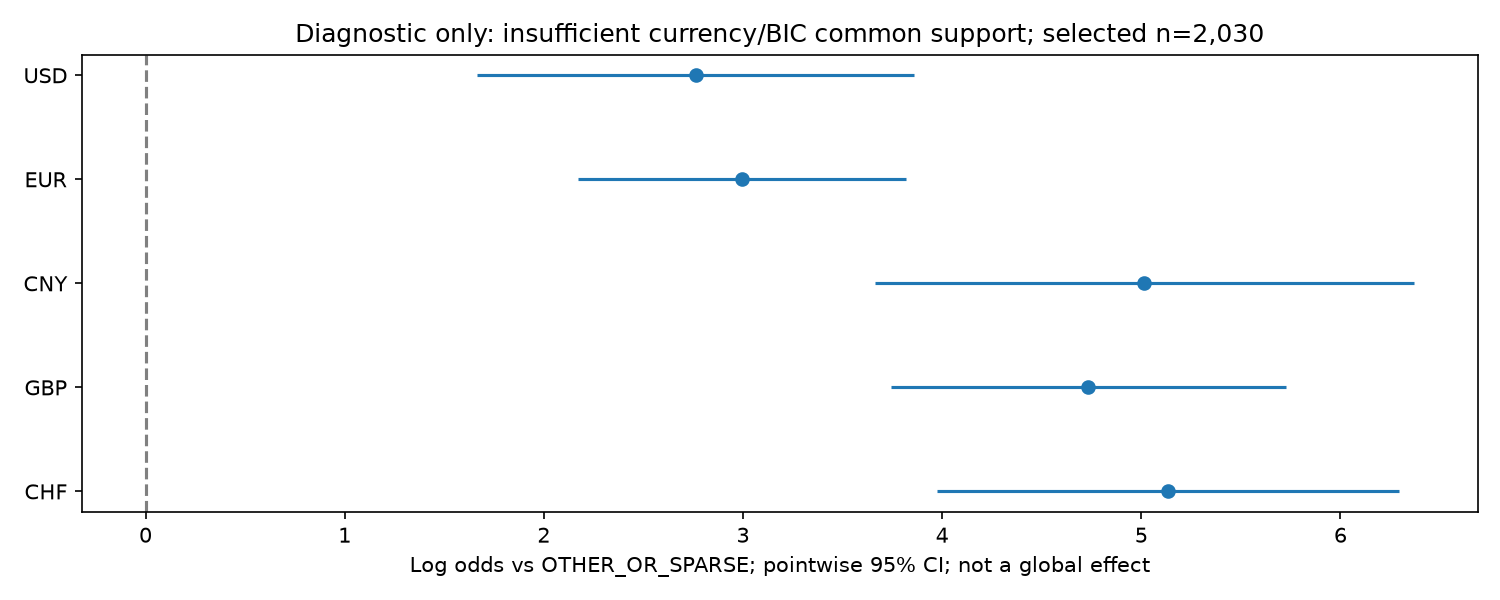

In [3]:
report = phase.finish(["Currency results: " + effects.to_json(orient="records"), "Model diagnostics: " + diagnostics.to_json(orient="records"), "Sparse/unsupported currencies are not promoted to rules."], ["Pointwise conditional uncertainty; no causal or external-validation claim.", "Restricted regression/common-support populations must not be generalized to the full network."])
display(Markdown("## Final findings and limitations\n" + "\n\n".join(report["findings"])))
display(Markdown("Generated tables: `" + str(phase.out.relative_to(ROOT)) + "`; charts: `" + str(phase.charts.relative_to(ROOT)) + "`. Source hashes and validation checks are in the completion manifest."))
for chart in sorted(phase.charts.glob("*.png")):
    display(Image(filename=str(chart)))
